# **Tabular Ad-Click Prediction Neural Network**

*Import and requirements*

In [6]:
!pip install --upgrade scikit-learn scikeras
!pip install --upgrade tensorflow
!pip install -r requirements.txt

In [7]:
# Imports
import numpy as np
import random
import pandas as pd
import tensorflow as tf
from keras.layers import *
from keras.models import Sequential
from keras import regularizers
import keras as K
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from scikeras.wrappers import KerasClassifier
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import *
import tensorflow as tf
import matplotlib.pyplot as plt

# Seeds
random.seed(123)
np.random.seed(123)
tf.random.set_seed(123)

# **2) INPUT**

## **2a) Preprocessing**

In [8]:
import zipfile

with zipfile.ZipFile("data/input_data.zip", 'r') as zip_ref:
     zip_ref.extractall("unzipped_data")
import pickle as pk
import numpy as np

with open("unzipped_data/input_data.pkl", "rb") as f:
     df = pk.load(f)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 953 entries, 0 to 999
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Daily Time Spent on Site  953 non-null    float64
 1   Age                       953 non-null    int64  
 2   Area Income               953 non-null    float64
 3   Daily Internet Usage      953 non-null    float64
 4   Ad Topic Line             953 non-null    object 
 5   City                      953 non-null    object 
 6   Male                      953 non-null    int64  
 7   Country                   953 non-null    object 
 8   Timestamp                 953 non-null    object 
 9   Clicked on Ad             953 non-null    int64  
 10  Search Queries            953 non-null    object 
dtypes: float64(3), int64(3), object(5)
memory usage: 89.3+ KB


**Target separation**

In [10]:
y = df['Clicked on Ad']
df = df.drop(columns=['Clicked on Ad'])

In [11]:
ad_top = df['Ad Topic Line'].nunique()
city = df['City'].nunique()
print(f'Number of unique values in Ad Topic Line: {ad_top}')
print(f'Number of unique values in City: {city}')

Number of unique values in Ad Topic Line: 953
Number of unique values in City: 926


**CHANGE**   
- I **also drop `'Ad Topic Line'`** because its number of unique values is equal to the number of samples in the dataset, keeping it would mean let the model learn the value of `'Ad Topic Line'` as an identifier of that sample, leading so to overfitting and low generalization capabilities.   
- I **also drop `'City'`** for the same reasons, it has 926 unique values over the 953 available samples. Given that other features are more informative for the task, the potential risks of keeping it into the dataset outweights its benefits.

In [12]:
df = df.drop(columns=['Timestamp', 'Ad Topic Line', 'City'])

**Split before any fitting**

In [13]:
X_train, X_test, y_train, y_test = train_test_split(df, y, test_size=0.25, stratify=y, random_state=123)
print(f'Shapes: \n X train: {X_train.shape}, \n X test: {X_test.shape}, \n y train:{y_train.shape}, \n y test: {y_test.shape}')

Shapes: 
 X train: (714, 7), 
 X test: (239, 7), 
 y train:(714,), 
 y test: (239,)


#### **Feature pools**

*Separate the features in train-features and test-features*  
- I will use categorical train-features to train the autoencoders and then the whole train-features (see section "2b)" ) to discover what is the best hyperparameter configuration of the whole classification model (the one that uses in input numerical features and latent dimension of the two autoencoders).

- I will use the whole test-features (gathered, again, in section "2b)" ) just at the end of the notebook to evaluate on truly unseen data the best configuration of the RandomSearch CV, the one that will compose the final model.

##### *Numerical pools*

**CHANGE**   
During the written part I inadvertently omitted from the set of numerical features `'Daily Time Spent On Site'`.
I, obvioously, take it into account because it can be beneficial for the tas,and I will apply to it the same preprocessing pipeline as the other numerical features in its pool.

In [14]:
# Numerical feature pool (train-test split)
num_features_train = X_train[['Daily Time Spent on Site', 'Age', 'Area Income', 'Daily Internet Usage']]
num_features_test = X_test[['Daily Time Spent on Site', 'Age', 'Area Income', 'Daily Internet Usage']]

# Male feature (train-test split)
male_train = X_train['Male']
male_test = X_test['Male']

num_features_train.describe()

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage
count,714.000000,714.000000,714.000000,714.000000
mean,64.858123,36.149860,55236.931961,179.379482
std,15.940460,8.758003,13241.131211,43.924053
min,32.600000,19.000000,13996.500000,104.780000
25%,50.442500,29.000000,47073.067500,138.582500
50%,68.250000,35.000000,57023.600000,180.995000
75%,78.525000,42.000000,65609.200000,219.535000
max,91.370000,61.000000,79484.800000,267.010000


##### *Categorical pools*

Preprocessing of the numerical features defined in the `Column Transformer` (in section "4)")

I transform input categorical features in one hot vectors with matching dimension with respect to unique values vector.   

I perform a `reindex` because the input layer dimension of the country autoencoder will be fixed to the number of unique values in `'Country'`. So this reindex serves to account for a possible problem of having in test set some additional dimension to the `'Country'` feature that we didn't encounter in the training set (but obviously have to be considered when encoding the test data with the pretrained autoencoder).

In [15]:
uniqCountries = sorted(df['Country'].astype(str).unique().tolist())

# Use sorted unique vectors to one hot encode training samples
countrOhe_train = pd.get_dummies(X_train['Country'])
countrOhe_train.sort_index(axis=1) # sort to perform reindexing and keeping
                                   # coherence with uniqCountries

countrOhe_test = pd.get_dummies(X_test['Country'])
countrOhe_test.sort_index(axis=1) # sort to perform reindexing and keeping
                                   # coherence with uniqCountries also for test


# Reindex both train and test to have one hot vectors with coherent dimensions
countrOhe_train = countrOhe_train.reindex(columns=uniqCountries, fill_value=0)
countrOhe_test  = countrOhe_test.reindex(columns=uniqCountries, fill_value=0)

countrOhe_train = countrOhe_train.astype('float32')
countrOhe_test = countrOhe_test.astype('float32')

countrOhe_train

,Afghanistan,Albania,Algeria,American Samoa,Andorra,Angola,Anguilla,Antarctica (the territory South of 60 deg S),Antigua and Barbuda,Argentina,...,Uruguay,Uzbekistan,Vanuatu,Venezuela,Vietnam,Wallis and Futuna,Western Sahara,Yemen,Zambia,Zimbabwe
861,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
888,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
979,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
265,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
657,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
407,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
383,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
954,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
425,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Extract the train-test split of `'Search Queries'`   
(no reindexing here because I do not have to perform any one/multi hot-vectorization and the vectors are all complete)

In [16]:
# Extract train-test split
sq_train = X_train['Search Queries']
sq_test = X_test['Search Queries']

In [17]:
print(sq_train.shape)
print(sq_test.shape)

(714,)
(239,)


Extract from each entry of the `sq_train`/`sq_test` vector the samples

In [18]:
sq_train = np.array(sq_train.tolist(), dtype=np.float32)
sq_test = np.array(sq_test.tolist(), dtype=np.float32)

In [19]:
print(sq_train.shape)
print(sq_test.shape)

(714, 300)
(239, 300)


### **Autoencoders for `'Country'` and `'Search Queries'`**

*Define the AE class*

In [20]:
def encoder(input_shape,
            encoding_dimension=10,
            dense_units=[150, 50]):
  enc = K.Sequential()
  enc.add(Input(shape=(input_shape,)))
  enc.add(Dense(dense_units[0], activation='relu', kernel_initializer='he_normal'))
  enc.add(Dense(dense_units[1], activation='relu', kernel_initializer='he_normal'))
  enc.add(Dense(encoding_dimension, activation='relu', kernel_initializer='he_normal'))
  return enc

def decoder(output_shape,
            output_activ='softmax',
            encoding_dimension=10,
            dense_units=[150,50]):
  dec = K.Sequential()
  dec.add(Input(shape=(encoding_dimension,)))
  dec.add(Dense(dense_units[1], activation='relu', kernel_initializer='he_normal'))
  dec.add(Dense(dense_units[0], activation='relu', kernel_initializer='he_normal'))
  dec.add(Dense(output_shape, input_shape=(encoding_dimension,), activation=output_activ))
  return dec

In [21]:
class AE(K.Model):
  def __init__(self, input_shape, encoding_dimension,
               enc_model, dec_model, dense_units=[150,50], output_activ='softmax', use_BN=False):
    super(AE, self).__init__()

    self.encoder = enc_model(input_shape,encoding_dimension,dense_units)
    self.decoder = dec_model(input_shape, output_activ, encoding_dimension, dense_units)




  def getEncodedSamples(self, samp):
        encoded_samples = self.encoder.predict(samp)
        return encoded_samples

  def call(self, input):
    out_encoder = self.encoder(input)
    out_decoder = self.decoder(out_encoder)
    return out_decoder

The goal of each autoencoder model is to reconstruct the input given, but in the training process the model learns compressed representations of the samples.   
For the classification task I will exploit this property of autoencoders to extract (with `getEncodedSamples`) lower dimensional embeddings of the samples (to be then used in the MLP that performs the classification).

#### *AE for `'Country'`*

In [22]:
inputShape_country_train = int(countrOhe_train.shape[1]) # Extract the input shape to define the autoencoder
encodingDim_country_train = 10                           # Define the encoding dimension

# Parameters for the Country AE
lr_country = 10e-3
batch_size_country = 64
epochs_country = 25

In [23]:
# Instantiate the Country AE
ae_country = AE(inputShape_country_train, encodingDim_country_train, encoder, decoder)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [24]:
ae_country.summary()

Model: "ae"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 10)             │        43,460 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (None, 235)            │        43,685 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 87,145 (340.41 KB)

 Trainable params: 87,145 (340.41 KB)

 Non-trainable params: 0 (0.00 B)

In [25]:
# Compile the AE with the above defined parameters
ae_country.compile(optimizer=K.optimizers.Adam(learning_rate=lr_country),
                   loss='categorical_crossentropy',
                   metrics=['accuracy'])

Train the autoencoder to reconstruct the input

In [26]:
# Train the Country AE
ae_country.fit(countrOhe_train, countrOhe_train,
               epochs=epochs_country,
               batch_size=batch_size_country)

Epoch 1/25
12/12 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.0185 - loss: 5.4033
Epoch 2/25
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.0834 - loss: 4.1590
Epoch 3/25
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.2615 - loss: 2.9284
Epoch 4/25
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.4149 - loss: 2.1453
Epoch 5/25
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.5350 - loss: 1.6863
Epoch 6/25
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.5946 - loss: 1.4664
Epoch 7/25
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.6911 - loss: 1.1752
Epoch 8/25
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.7104 - loss: 1.0951
Epoch 9/25
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.7196 - loss: 0.9238
Epoch 10/25
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.7809 - loss: 0.7965
Epoch 11/25
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.8010 - loss: 0.7388
Epoch 12/25
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy:

Check that the autoencoder works in shrinking the dimension of the input vector into the latent space dimension:

In [27]:
countrOhe_train.shape

(714, 235)

In [28]:
ae_country.getEncodedSamples(countrOhe_train).shape

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step


(714, 10)

#### *AE for `'Search Queries'`*   

`'Search Queries'` contains **multi-hot vectors** each of dimension 300

In [29]:
inputShape_sq_train = len(sq_train[0]) # Extract the input shape to define the autoencoder
encodingDim_sq_train = 10              # Define the encoding dimension

# Parameters for the Search Queries AE
lr_sq = 1e-3
batch_size_sq = 64
epochs_sq= 40

**CHANGE**   
As activation of the last layer of the autoencoder for `'Search Queries'` (dim. of the layer=300) I use a sigmoid for each unit so that we can let the model learn the reconstruction of each of the 300 entries of the output vector (since it is a multi-hot vector)

In [30]:
# Instantiate the Search Queries AE
ae_sq = AE(inputShape_sq_train, encodingDim_sq_train, encoder, decoder, dense_units=[175,60], output_activ='sigmoid')

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [31]:
ae_sq.summary()

Model: "ae_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_2 (Sequential)       │ (None, 10)             │        63,845 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_3 (Sequential)       │ (None, 300)            │        64,135 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 127,980 (499.92 KB)

 Trainable params: 127,980 (499.92 KB)

 Non-trainable params: 0 (0.00 B)

**CHANGE**   
Since the vectors in `'Search Queries'` are multi-hot vectors, I use `binary_accuracy` because the task of the autoencoder is to accurately reconstruct the input vector's presence or absence of each feature.

In [32]:
# Compile the AE with the above defined parameters
ae_sq.compile(optimizer=K.optimizers.Adam(learning_rate=lr_sq),
                   loss='binary_crossentropy',
                   metrics=['binary_accuracy'])

In [33]:
# Train the Search Queries AE
ae_sq.fit(sq_train, sq_train,
          epochs=epochs_sq,
          batch_size=batch_size_sq)

Epoch 1/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - binary_accuracy: 0.6166 - loss: 0.6690
Epoch 2/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - binary_accuracy: 0.9305 - loss: 0.3553
Epoch 3/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - binary_accuracy: 0.9505 - loss: 0.2470
Epoch 4/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - binary_accuracy: 0.9505 - loss: 0.2134
Epoch 5/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - binary_accuracy: 0.9505 - loss: 0.2060
Epoch 6/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - binary_accuracy: 0.9505 - loss: 0.2028
Epoch 7/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - binary_accuracy: 0.9505 - loss: 0.2003
Epoch 8/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - binary_accuracy: 0.9505 - loss: 0.1981
Epoch 9/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - binary_accuracy: 0.9505 - loss: 0.1963
Epoch 10/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - binary_accuracy: 0.9505 - loss: 0.1947
Epoch 11/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - binary_accuracy: 0.9505 -

Check that the autoencoder works in shrinking the dimension of the input vector into the latent space dimension:

In [34]:
sq_train.shape

(714, 300)

In [35]:
ae_sq.getEncodedSamples(sq_train).shape

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


(714, 10)

## **2b) Input of the model**

**CHANGE**   
Instead of having the concatenation of the three inputs inside the model (and then pass a dictionary to the `.fit` method), I put them outside because of encountered problems of `RandomSearchCV` in handling the dimension of the input when `.fit` is performed.

In [36]:
# First perform encoding of categorical features
country_enc_train = ae_country.getEncodedSamples(countrOhe_train)
sq_enc_train = ae_sq.getEncodedSamples(sq_train)

# Then concatenate this with the raw numerical columns (carefully with 'Male')
num_feat_train = [num_features_train, male_train.values.reshape(-1, 1)]
num_X_train = np.concatenate(num_feat_train, axis=1)
X_train_halfRaw = np.concatenate((num_X_train, country_enc_train, sq_enc_train), axis=1)

print(f'Numerical features dimensions: \n Numerical train: {num_X_train.shape}')
print(f'\nCategorical features dimensions: \n Country train: {country_enc_train.shape} \n Search Queries train: {sq_enc_train.shape}')
print(f'\nTotal (concatenated) dimensions train: {X_train_halfRaw.shape}')

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Numerical features dimensions: 
 Numerical train: (714, 5)

Categorical features dimensions: 
 Country train: (714, 10) 
 Search Queries train: (714, 10)

Total (concatenated) dimensions train: (714, 25)


# **3) OUTPUT and LOSS**  and  **4) MODEL CONFIGURATION**

In [37]:
# a) Model overall composition
def create_model(nhid1=20, nhid2=16,
                 learning_rate = 1e-3,
                 metrics = ['accuracy'],
                 hid_act = 'relu',
                 ker_init = 'he_normal',
                 out_act='sigmoid',
                 dropout_rate=0.1, # Added dropout_rate parameter
                 weight_reg=regularizers.L2(10e-3),
                 clipvalue=None):

  input_dim = 25
  inp = Input(shape=(input_dim,))
  d1 = Dense(nhid1, activation=hid_act, kernel_initializer=ker_init, kernel_regularizer=weight_reg)(inp)
  dr1 = Dropout(dropout_rate)(d1)
  d2 = Dense(nhid2, activation=hid_act, kernel_initializer=ker_init, kernel_regularizer=weight_reg)(dr1)
  #dr2 = Dropout(dropout_rate)(d3)
  #d3 = Dense(nhid3, activation=hid_act, kernel_initializer=ker_init, kernel_regularizer=weight_reg)(dr2)
  out = Dense(1, activation='sigmoid')(d2) # 3) Output unit with sigmoid activation

  model = K.Model(inputs=inp, outputs=out)

  model.compile(optimizer=K.optimizers.Adam(learning_rate=learning_rate, clipvalue=clipvalue),
                loss='binary_crossentropy', # ) BCE as loss function
                metrics=metrics)

  return model

I have tested also a **3 layer architecture** that showed to be too complex for the task and data available, and even by searching the best parameters it would **inevitably lead to high overfitting**. The 3 layer architecture showed **poor generalization capabilities** letting the model memorize patterns in training instead of extracting general features of data.   
Therefore I have chosen, and properly tested, a **2 layer architecture to address the classification problem**.

## **4b) Model configuration to optimize performances**

I chose to let `RandomSearch CV` work on these parameters, the dropout and regularizer have turned out to be essential in preventing the model from overfitting. I try also many configurations for the number of units of the two layers, higher number of units have been tested leading the model chosen to overfitting and poor generalization capabilities.

In [38]:
# Search spaces for hyperparameters
param_distribs = {
    'model__nhid1': [12, 16, 20],
    'model__nhid2': [8, 12],
    #'model__nhid3': [8, 16],
    'model__learning_rate': loguniform(1e-4, 5e-3),
    'model__dropout_rate': uniform(0.2, 0.45),
    'model__weight_reg': [regularizers.L2(1e-2), regularizers.L2(1e-1)], #regularizers.L2(1e-3),
    'model__batch_size': [32, 64],
    'model__epochs': [25],
    'model__clipvalue': uniform(0.5, 2.0)
}

By placing the `Standard Scaler` within in the `Column Transformer`, of the cross-validation pipeline, I ensure that the `Random Search CV` perform the appropriate scaling separately on the training data of eac cross-validation fold so to prevent any leak about the validation fold to the model's training.   
 I chose not to apply this fold-specific fitting for the categorical features because it would have required to train the autoencoders on each of the cross-validation training folds for every hyperparameter combination and this would have led to a too high computational cost and much higher running times.

In [39]:
# Prepare indices to let the CV apply scaling only on numerical features
num_cols_tbPrepr = [0, 1, 2, 3]
cat_cols_alrPrepr = list(range(4, X_train_halfRaw.shape[1]))


# 4a) Model Pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('Numerical Scaling', StandardScaler(), num_cols_tbPrepr),
        ('Categorical Features', 'passthrough', cat_cols_alrPrepr)
    ])

# Instantiate the model pipeline
pipeline = Pipeline(steps=[('Preprocessing', preprocessor),
                           ('model', KerasClassifier(model=create_model, nhid1=20, nhid2=16, weight_reg=regularizers.L2(1e-1), learning_rate=1e-2, dropout_rate=0.2, clipvalue=1))])

In [40]:
# Instantiate the RandomSearchCV
randSearch_CV = RandomizedSearchCV(estimator=pipeline,
                                   param_distributions=param_distribs,
                                   n_iter=7, # In case of not 5-mins-run lower this by 1
                                   cv=4,
                                   random_state=123,
                                   verbose=2)

The `RandomSearch CV` creates a number of models equal to the number of iterations, each with a different hyperparameter setting. For each model it performs a cross-validation with 4 folds in order to train the model on different parts of the training set and extract as much information as possible from training data (crucial in our case because we have less than 1k samples).  
I chose to perform 4 splits for each configuration exactly for this reason above.

In [41]:
# Train the RandomSearchCV
randomSearch_history = randSearch_CV.fit(X_train_halfRaw, y_train)

Fitting 4 folds for each of 7 candidates, totalling 28 fits
Epoch 1/25
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4657 - loss: 2.0708
Epoch 2/25
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4980 - loss: 1.8243 
Epoch 3/25
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5001 - loss: 1.4847 
Epoch 4/25
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5296 - loss: 1.3817 
Epoch 5/25
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5728 - loss: 1.2984 
Epoch 6/25
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6776 - loss: 1.1400 
Epoch 7/25
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6829 - loss: 1.1059 
Epoch 8/25
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7405 - loss: 1.0058 
Epoch 9/25
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7377 - loss: 0.9833 
Epoch 10/25
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7703 - loss: 0.9210 
Epoch 11/25
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7935 - loss: 0.8546 
Epoc

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
[CV] END model__batch_size=32, model__clipvalue=1.9259106410464544, model__dropout_rate=0.39281191678407157, model__epochs=25, model__learning_rate=0.0014920818417140844, model__nhid1=16, model__nhid2=12, model__weight_reg=<keras.src.regularizers.regularizers.L2 object at 0x794f3a7e4e00>; total time=   3.9s
Epoch 1/25
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.6216 - loss: 1.4688
Epoch 2/25
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6589 - loss: 1.2271 
Epoch 3/25
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7409 - loss: 1.0137 
Epoch 4/25
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7349 - loss: 0.9589 
Epoch 5/25
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8071 - loss: 0.9067 
Epoch 6/25
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7874 - loss: 0.8611 
Epoch 7/25
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8342 - loss: 0.8186 
Epoch 8/25
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accurac

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
[CV] END model__batch_size=32, model__clipvalue=1.9259106410464544, model__dropout_rate=0.39281191678407157, model__epochs=25, model__learning_rate=0.0014920818417140844, model__nhid1=16, model__nhid2=12, model__weight_reg=<keras.src.regularizers.regularizers.L2 object at 0x794f3a7e4e00>; total time=   4.1s
Epoch 1/25
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5151 - loss: 1.3927
Epoch 2/25
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5189 - loss: 1.3152 
Epoch 3/25
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5627 - loss: 1.2348 
Epoch 4/25
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5019 - loss: 1.2310 
Epoch 5/25
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5468 - loss: 1.1732 
Epoch 6/25
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5896 - loss: 1.1377 
Epoch 7/25
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5870 - loss: 1.0992 
Epoch 8/25
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6004 - los

# **5) MODEL EVALUATION**

In order to assess the generalization capabilities of the model (i.e. the ability of the model to classify correctly even completely unseen data), as last step of the whole project, I take the best model that `RandomSearch CV` have chosen and, after a correct transform of all the test data, I feed the model with both train and test data (test as validation).

In [42]:
# Extract and read the parameters of the best model chosen by RandomSearchCV
bestParams = randSearch_CV.best_params_
bestScore = randSearch_CV.best_score_
print("Best parameters found:")
for key in bestParams:
  print(f'{key} : {bestParams[key]}')
print(f"\nBest CV score:\n{bestScore}")

Best parameters found:
model__batch_size : 32
model__clipvalue : 1.9259106410464544
model__dropout_rate : 0.39281191678407157
model__epochs : 25
model__learning_rate : 0.0014920818417140844
model__nhid1 : 16
model__nhid2 : 12
model__weight_reg : <keras.src.regularizers.regularizers.L2 object at 0x794f3a7e4e00>

Best CV score:
0.959395204318624


In [43]:
bestEstim = randSearch_CV.best_estimator_

country_enc_test = ae_country.getEncodedSamples(countrOhe_test)
sq_enc_test = ae_sq.getEncodedSamples(sq_test)
num_feat_test = [num_features_test, male_test.values.reshape(-1, 1)]
num_X_test = np.concatenate(num_feat_test, axis=1)

# Concatenate carefully (wrt the order) the three pools
X_test_halfRaw = np.concatenate((num_X_test, country_enc_test, sq_enc_test), axis=1)
X_test_prep = bestEstim.named_steps['Preprocessing'].transform(X_test_halfRaw)

best_BS = bestEstim.named_steps['model'].batch_size

bestEstim_history = bestEstim.fit(
    X_train_halfRaw,
    y_train,
    model__epochs=30,
    model__batch_size=best_BS,
    model__validation_data=(X_test_prep, y_test) # Use manually preprocessed test data for validation
)

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
Epoch 1/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.4839 - loss: 1.9633 - val_accuracy: 0.5105 - val_loss: 1.2415
Epoch 2/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5371 - loss: 1.3803 - val_accuracy: 0.6778 - val_loss: 1.0942
Epoch 3/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5503 - loss: 1.1689 - val_accuracy: 0.6862 - val_loss: 1.0303
Epoch 4/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6381 - loss: 1.0517 - val_accuracy: 0.7113 - val_loss: 0.9693
Epoch 5/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6767 - loss: 0.9807 - val_accuracy: 0.7364 - val_loss: 0.9002
Epoch 6/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7199 - loss: 0.9124 - val_accuracy: 0.8326 - val_loss: 0.8176
Epoch 7/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7644 - loss: 0.8389 - val_accuracy: 0.8745 - val_loss: 0.7334
Epoch 8/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 

To visualize the performances on unseen data of the best model I plot loss and accuracy.

In [44]:
# Store the model steps in order to construct the next two plots
historyBest = bestEstim.named_steps['model'].model_.history

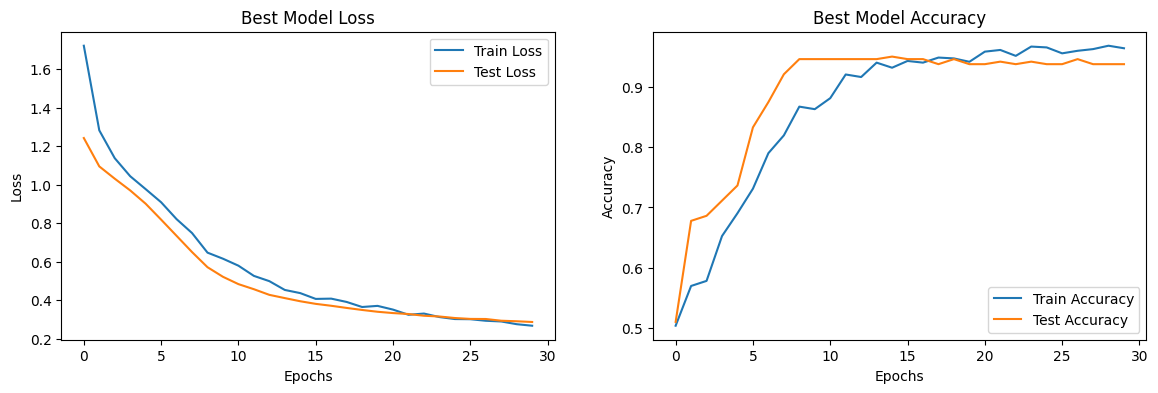

In [45]:
# Loss Plot
plt.figure(figsize=(14, 4))
plt.subplot(1, 2, 1)
plt.plot(historyBest.history['loss'], label='Train Loss')
plt.plot(historyBest.history['val_loss'], label='Test Loss')
plt.title('Best Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

# Accuracy Plot
plt.subplot(1, 2, 2)
plt.plot(historyBest.history['accuracy'], label='Train Accuracy')
plt.plot(historyBest.history['val_accuracy'], label='Test Accuracy')
plt.title('Best Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()